In [25]:
!pip install pyeasyga

In [26]:
from pyeasyga.pyeasyga import GeneticAlgorithm
from pyeasyga import pyeasyga
import random
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Zadatak 1

In [27]:
def criteria_function(x):
    x1 = x[0]
    x2 = x[1]
    return 20 + x1**2 + x2**2 - 10 * (np.cos(2 * np.pi * x1) + np.cos(2 * np.pi * x2))

In [28]:
RANGE = np.array([[-5.12, 5.12], [-5.12, 5.12]])

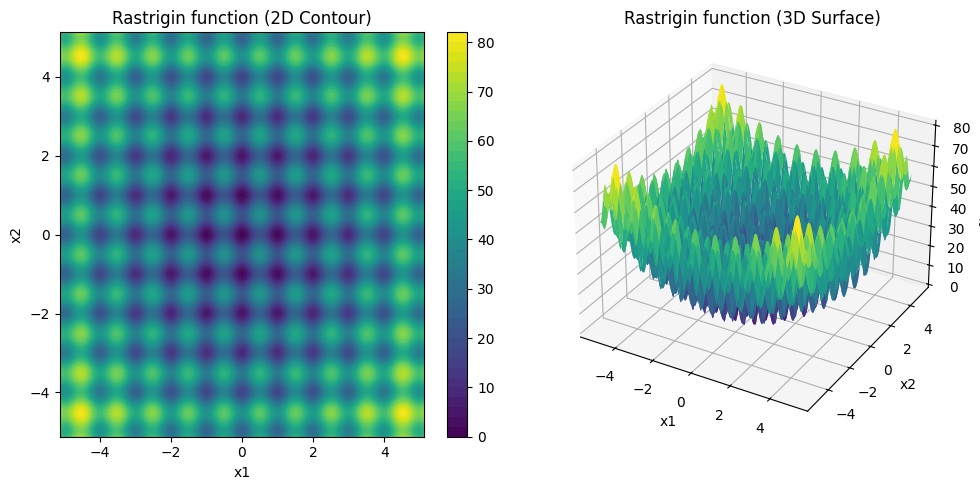

In [29]:
x = np.linspace(RANGE[0][0], RANGE[0][1], 400)
y = np.linspace(RANGE[1][0], RANGE[1][1], 400)
X, Y = np.meshgrid(x, y)
Z = criteria_function([X, Y])

fig = plt.figure(figsize=(10, 5))

ax1 = fig.add_subplot(1, 2, 1)
cp = ax1.contourf(X, Y, Z, levels=50, cmap='viridis')
fig.colorbar(cp, ax=ax1)
ax1.set_title('Rastrigin function (2D Contour)')
ax1.set_xlabel('x1')
ax1.set_ylabel('x2')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none')
ax2.set_title('Rastrigin function (3D Surface)')
ax2.set_xlabel('x1')
ax2.set_ylabel('x2')
ax2.set_zlabel('f(x1, x2)')

plt.tight_layout()
plt.show()

In [30]:
ga = GeneticAlgorithm(
    seed_data=criteria_function,
    population_size=30,
    generations=200,
    crossover_probability=0.8,
    mutation_probability=0.1,
    elitism=True,
    maximise_fitness=False
)

In [31]:
BINARY_CHROMOSOME_LENGTH = 6

In [32]:
def create_individual(data):
    return [random.randint(0, 1) for _ in range(BINARY_CHROMOSOME_LENGTH)]

In [33]:
ga.create_individual = create_individual

In [34]:
def crossover(parent_1, parent_2):
    crossover_index1 = random.randrange(1, len(parent_1) - 1)
    crossover_index2 = random.randrange(crossover_index1 + 1, len(parent_1))
    child_1 = parent_1[:crossover_index1] + parent_2[crossover_index1:crossover_index2] + parent_1[crossover_index2:]
    child_2 = parent_2[:crossover_index1] + parent_1[crossover_index1:crossover_index2] + parent_2[crossover_index2:]
    return child_1, child_2

In [35]:
ga.crossover_function = crossover

In [36]:
def mutate(individual):
    mutate_index = random.randrange(len(individual))
    if individual[mutate_index] == 0:
        individual[mutate_index] = 1
    else:
        individual[mutate_index] = 0

In [37]:
ga.mutate_function = mutate

In [38]:
ga.tournament_size = 2

In [39]:
def decimal(binary):
    sum = 0
    for i in range(0, len(binary)):
        sum += binary[len(binary) - 1 - i] * 2 ** (i)
    return sum

In [40]:
def decode(individual):
    x_binary = individual[:BINARY_CHROMOSOME_LENGTH // 2]
    y_binary = individual[BINARY_CHROMOSOME_LENGTH // 2:]
    x_range = RANGE[0]
    y_range = RANGE[1]
    x_min = x_range[0]
    x_max = x_range[1]
    y_min = y_range[0]
    y_max = y_range[1]
    x_decode = x_min + ((x_max - x_min) * decimal(x_binary)) / (2 ** (len(x_binary)) - 1)
    y_decode = y_min + ((y_max - y_min) * decimal(y_binary)) / (2 ** (len(y_binary)) - 1)
    return x_decode, y_decode

In [41]:
def is_in_range(x, range_x):
    return x >= range_x[0] and x <= range_x[1]

In [42]:
def fitness(individual, data):
    x_decode, y_decode = decode(individual)
    while not (is_in_range(x_decode, RANGE[0]) and is_in_range(y_decode, RANGE[1])):
        individual = create_individual(data)
        x_decode, y_decode = decode(individual)
    fitness = data([x_decode, y_decode])
    return fitness

In [43]:
ga.fitness_function = fitness

In [44]:
ga.run()

In [45]:
print("Best individual fitness and best individual binary chromosome:")
print(ga.best_individual())

print("Best individual decoded:")
print(decode(ga.best_individual()[1]))

print("Best individual function value:")
print(criteria_function(decode(ga.best_individual()[1])))

print("\n---------------------------\n")

print("Last generation:")
for individual in ga.last_generation():
    print(individual)

Best individual fitness and best individual binary chromosome:
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
Best individual decoded:
(np.float64(-2.1942857142857144), np.float64(-2.1942857142857144))
Best individual function value:
22.77063643875411

---------------------------

Last generation:
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063643875411), [0, 1, 0, 0, 1, 0])
(np.float64(22.77063

# Zadatak 2

In [46]:
# setup seed data
seed_data = [0, 1, 2, 3, 4, 5, 6, 7]

# initialise the GA
ga = pyeasyga.GeneticAlgorithm(
    seed_data,
    population_size=200,
    generations=100,
    crossover_probability=0.8,
    mutation_probability=0.2,
    elitism=True,
    maximise_fitness=False
)

# define and set function to create a candidate solution representation
def create_individual(data):
    individual = data[:]
    random.shuffle(individual)
    return individual

ga.create_individual = create_individual

# define and set the GA's crossover operation
def crossover(parent_1, parent_2):
    crossover_index = random.randrange(1, len(parent_1))
    child_1a = parent_1[:crossover_index]
    child_1b = [i for i in parent_2 if i not in child_1a]
    child_1 = child_1a + child_1b

    child_2a = parent_2[crossover_index:]
    child_2b = [i for i in parent_1 if i not in child_2a]
    child_2 = child_2a + child_2b

    return child_1, child_2

ga.crossover_function = crossover

# define and set the GA's mutation operation
def mutate(individual):
    mutate_index1 = random.randrange(len(individual))
    mutate_index2 = random.randrange(len(individual))
    individual[mutate_index1], individual[mutate_index2] = individual[mutate_index2], individual[mutate_index1]

ga.mutate_function = mutate

# define and set the GA's selection operation
def selection(population):
    return random.choice(population)

ga.selection_function = selection

# define a fitness function
def fitness(individual, data):
    collisions = 0
    for item in individual:
        item_index = individual.index(item)
        for elem in individual:
            elem_index = individual.index(elem)
            if item_index != elem_index:
                if item - (elem_index - item_index) == elem \
                    or (elem_index - item_index) + item == elem:
                    collisions += 1
    return collisions

ga.fitness_function = fitness       # set the GA's fitness function
ga.run()                            # run the GA

# function to print out chess board with queens placed in position
def print_board(board_representation):
    def print_x_in_row(row_length, x_position):
        print('', end='')
        for _ in range(row_length):
            print('---', end='')
        print('\n|', end='')
        for i in range(row_length):
            if i == x_position:
                print('{} |'.format('X'), end='')
            else:
                print('  |', end='')
        print('')

    def print_board_bottom(row_length):
        print('', end='')
        for _ in range(row_length):
            print('---', end='')

    num_of_rows = len(board_representation)
    row_length = num_of_rows    #rows == columns in a chessboard

    for row in range(num_of_rows):
        print_x_in_row(row_length, board_representation[row])

    print_board_bottom(row_length)
    print('\n')

# print the GA's best solution; a solution is valid only if there are no collisions
if ga.best_individual()[0] == 0:
    print(ga.best_individual())
    print_board(ga.best_individual()[1])
else:
    print(None)

(0, [3, 5, 0, 4, 1, 7, 2, 6])
------------------------
|  |  |  |X |  |  |  |  |
------------------------
|  |  |  |  |  |X |  |  |
------------------------
|X |  |  |  |  |  |  |  |
------------------------
|  |  |  |  |X |  |  |  |
------------------------
|  |X |  |  |  |  |  |  |
------------------------
|  |  |  |  |  |  |  |X |
------------------------
|  |  |X |  |  |  |  |  |
------------------------
|  |  |  |  |  |  |X |  |
------------------------

